<!-- DOC-BANNER -->
# Understanding Your Data (Day 19)

> **Playlist:** CampusX Day 19 *Understanding Your Data*.
> **Purpose:** First-look EDA on Titanic (`E:/MACHINE_LEARNING/train.csv`, 891 rows x 12 cols): shape, `sample(5)`, `info` (Age 714/Cabin 204/Embarked 889 non-null), `isnull` (Age 177, Cabin 687, Embarked 2), `describe`, `duplicated.sum()` = 0, `corr(numeric_only=True)` + annotated heatmap.
> **Prerequisites:** DataFrame basics, what null/duplicate/correlation mean (intuition only).
> **After studying:** you can run the standard 7-step first look on any new CSV.


## First look at the Titanic data

Seven quick checks (size, glimpse, types, missing, stats, duplicates, correlations) before any modeling.


In [21]:
import pandas as pd 

In [22]:
df = pd.read_csv(r"E:\MACHINE_LEARNING\train.csv")

### Dataset size: rows and columns

`shape` tells us how much data we have to learn from.


In [23]:
df.shape

(891, 12)

### Glimpse: first and random rows

`head` shows the top; `sample(5)` shows random rows and better reveals variety.


### 1. Size and glimpses — `shape`, `sample(5)`
`shape` gives (rows, cols); `sample(5)` shows random rows (better than `head` alone for spotting variety).

In [24]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
721,722,0,3,"Jensen, Mr. Svend Lauritz",male,17.0,1,0,350048,7.0542,NaN,S
838,839,1,3,"Chip, Mr. Chang",male,32.0,0,0,1601,56.4958,NaN,S
819,820,0,3,"Skoog, Master. Karl Thorsten",male,10.0,3,2,347088,27.9000,NaN,S
372,373,0,3,"Beavan, Mr. William Thomas",male,19.0,0,0,323951,8.0500,NaN,S
220,221,1,3,"Sunderland, Mr. Victor Francis",male,16.0,0,0,SOTON/OQ 392089,8.0500,NaN,S


### Column types and non-null counts (`info`)

Reveals which columns have gaps (Age, Cabin, Embarked) and which dtypes need converting.


### 2. Missing-value hunt — `info`, `isnull().sum()`
`info()` reveals Age/Cabin/Embarked gaps; `isnull().sum()` quantifies them. Expect: Cabin mostly missing (drop or engineer), Age moderately missing (impute later), Embarked 2 missing (mode impute).

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### Count missing values per column

`isnull().sum()` turns the gaps into exact numbers that decide the treatment.


In [26]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Numeric summary (`describe`)

Count, mean, spread and quartiles per numeric column — the mathematical fingerprint of the data.


### 3. Math summary — `describe`, `duplicated`, `corr` + heatmap
`describe()` = count/mean/std/min/quartiles/max for numerics. `duplicated().sum()` = 0 means no full-duplicate rows. `corr(numeric_only=True)` + `sns.heatmap(annot=True)` shows numeric linear links — read numbers, not just colors. Kernel crashed after the heatmap render; re-run is safe (read-only).

In [27]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Check duplicate rows

`duplicated().sum()` counts fully identical rows (here: none).


In [28]:
df.duplicated().sum()

np.int64(0)

### Correlation between numeric columns

`corr()` measures linear links (-1..1); the annotated heatmap makes the numbers readable.


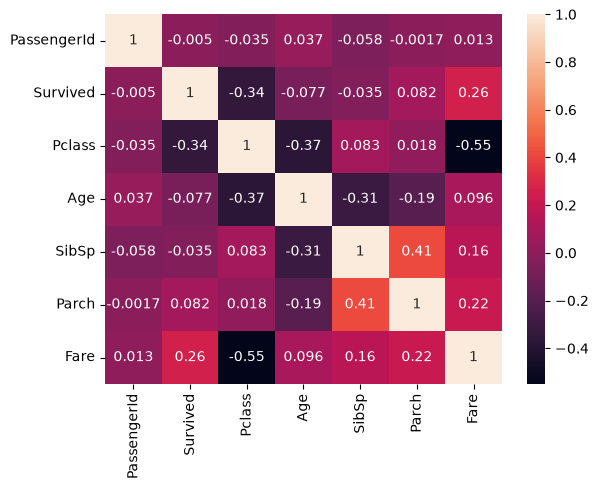

: 

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

<!-- EXPERIMENT -->
### Experiment: turn counts into decisions
Compute the missing *percentage* per column (`isnull().mean() * 100`). Predict: which column crosses 50% (drop/engineer territory) and which sits near 20% (impute territory)? Then `drop` the worst column and re-check `shape` — how many columns remain?

<!-- DOC-BANNER -->
## Key takeaways (Day 19)
- Order: size → glimpse → missing → math → duplicates → correlations.
- **Interpretation:** 891x12; Age/Cabin need treatment; no duplicate rows; correlation values near 0 mean weak linear relation (check the annotated numbers).
- **ML connection:** Data collection → inspection. Cleaning/imputation (Days 23-28) depend on the missing-value table produced here.
